<a href="https://colab.research.google.com/github/donggeunlee77/R-exercise/blob/main/R-Negative-binomial-regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Negative binomial regression with R

https://stats.oarc.ucla.edu/r/dae/negative-binomial-regression/

In [1]:
install.packages("foreign")
install.packages("ggplot2")
install.packages("MASS")
library(foreign)
library(ggplot2)
library(MASS)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
dat <- read.dta("https://stats.idre.ucla.edu/stat/stata/dae/nb_data.dta")

dat <- within(dat, {
  prog <- factor(prog, levels = 1:3, labels=c("General", "Academic", "Vocational"))
  id <- factor(id)
})

In [3]:
summary(dat)

       id         gender         math          daysabs               prog    
 1001   :  1   female:160   Min.   : 1.00   Min.   : 0.000   General   : 40  
 1002   :  1   male  :154   1st Qu.:28.00   1st Qu.: 1.000   Academic  :167  
 1003   :  1                Median :48.00   Median : 4.000   Vocational:107  
 1004   :  1                Mean   :48.27   Mean   : 5.955                   
 1005   :  1                3rd Qu.:70.00   3rd Qu.: 8.000                   
 1006   :  1                Max.   :99.00   Max.   :35.000                   
 (Other):308                                                                 

In [4]:
head(dat)

,id,gender,math,daysabs,prog
,<fct>,<fct>,<dbl>,<dbl>,<fct>
1,1001,male,63,4,Academic
2,1002,male,27,4,Academic
3,1003,female,20,2,Academic
4,1004,female,16,3,Academic
5,1005,female,2,3,Academic
6,1006,female,71,13,Academic


In [5]:
nrow(dat)

[1] 314

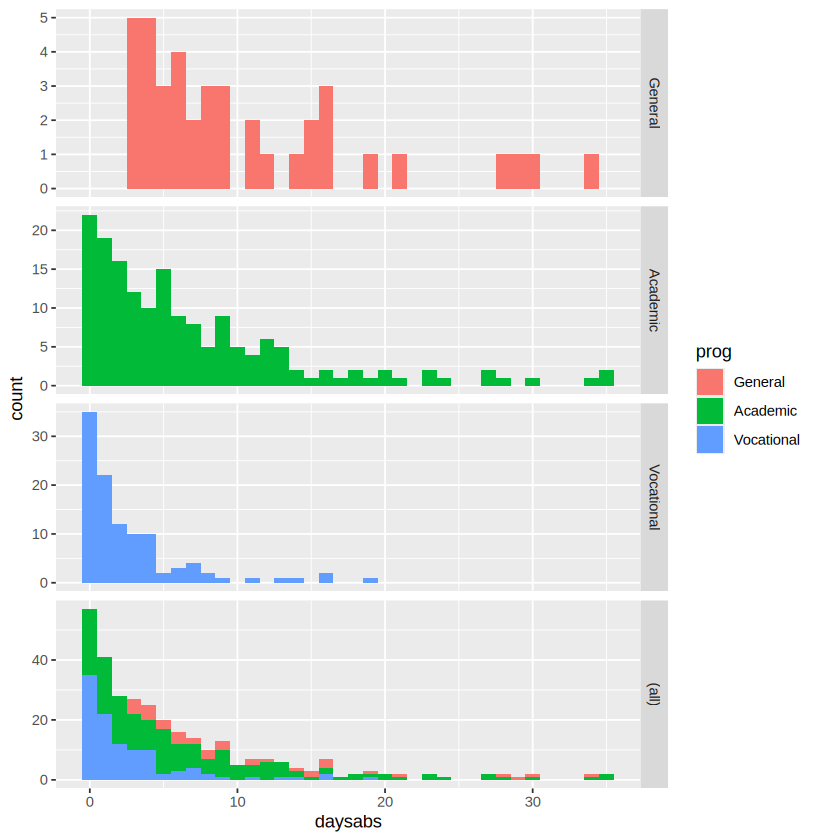

In [11]:
ggplot(dat, aes(daysabs, fill=prog))+
  geom_histogram(binwidth=1)+
  facet_grid(prog~., margins=TRUE, scales='free')

In [12]:
with(dat, tapply(daysabs, prog, function(x) {
    sprintf("M (SD) = %1.2f (%1.2f)", mean(x), sd(x))
}))

General                Academic              Vocational 
"M (SD) = 10.65 (8.20)"  "M (SD) = 6.93 (7.45)"  "M (SD) = 2.67 (3.73)"

In [13]:
m1 <- glm.nb(daysabs ~ math + prog, data = dat)
m1


Call:  glm.nb(formula = daysabs ~ math + prog, data = dat, init.theta = 1.032713156, 
    link = log)

Coefficients:
   (Intercept)            math    progAcademic  progVocational  
      2.615265       -0.005993       -0.440760       -1.278651  

Degrees of Freedom: 313 Total (i.e. Null);  310 Residual
Null Deviance:	    427.5 
Residual Deviance: 358.5 	AIC: 1741

In [14]:
summary(m1)


Call:
glm.nb(formula = daysabs ~ math + prog, data = dat, init.theta = 1.032713156, 
    link = log)

Coefficients:
                Estimate Std. Error z value Pr(>|z|)    
(Intercept)     2.615265   0.197460  13.245  < 2e-16 ***
math           -0.005993   0.002505  -2.392   0.0167 *  
progAcademic   -0.440760   0.182610  -2.414   0.0158 *  
progVocational -1.278651   0.200720  -6.370 1.89e-10 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for Negative Binomial(1.0327) family taken to be 1)

    Null deviance: 427.54  on 313  degrees of freedom
Residual deviance: 358.52  on 310  degrees of freedom
AIC: 1741.3

Number of Fisher Scoring iterations: 1


              Theta:  1.033 
          Std. Err.:  0.106 

 2 x log-likelihood:  -1731.258 

Theta는 dispersion parameter (tilestat 참고) 인데, SAS, Stata, SPSS가 이 dispersion parameter를 각각 다르게 계산하니 참고할것.
The R parameter
(theta) is equal to the inverse of the dispersion parameter (alpha)
estimated in these other software packages.
Thus, the theta value of 1.033
seen here is equivalent to the 0.968 value seen in the
Stata Negative Binomial
Data Analysis Example (https://stats.oarc.ucla.edu/stata/dae/negative-binomial-regression/) because 1/0.968 = 1.033.

다음은 prog의 가치를 따로 확인하기

In [15]:
m2 <- update(m1, .~. - prog)
anova(m1, m2)

Model,theta,Resid. df,2 x log-lik.,Test,df,LR stat.,Pr(Chi)
<chr>,<dbl>,<int>,<dbl>,<chr>,<int>,<dbl>,<dbl>
math,0.8558565,312,-1776.306,,NA,NA,NA
math + prog,1.0327132,310,-1731.258,1 vs 2,2,45.04798,1.65179e-10


The two degree-of-freedom chi-square test indicates that prog is
a statistically significant predictor of daysabs.

# Checking model assumption
As we mentioned earlier, negative binomial models assume the conditional means
are not equal to the conditional variances. This inequality is captured by
estimating a dispersion parameter (not shown in the output) that is held
constant in a Poisson model. Thus, the Poisson
model is actually nested in the negative binomial model. We can then use a
likelihood ratio test to compare these two and test this model assumption. To do this, we will run our model as
a Poisson.

In [16]:
m3 <- glm(daysabs ~ math + prog, family = "poisson", data=dat)
pchisq(2* (logLik(m1) - logLik(m3)), df = 1, lower.tail=FALSE)

'log Lik.' 2.157298e-203 (df=5)

In this example the associated chi-squared value estimated from 2*(logLik(m1) – logLik(m3)) is 926.03 with one degree
of freedom. This strongly suggests the negative binomial model,
estimating the dispersion parameter, is more
appropriate than the Poisson model.

In [25]:
coef(m1)
confint(m1)

(Intercept)           math   progAcademic progVocational 
   2.615265446   -0.005992988   -0.440760012   -1.278650721

Waiting for profiling to be done...



,2.5 %,97.5 %
(Intercept),2.24205576,3.012935926
math,-0.01090086,-0.001066615
progAcademic,-0.81006586,-0.092643481
progVocational,-1.68348970,-0.890077623


In [26]:
est <- cbind(Estimate = coef(m1), confint(m1))

Waiting for profiling to be done...



In [20]:
est

,Estimate,2.5 %,97.5 %
(Intercept),2.615265446,2.24205576,3.012935926
math,-0.005992988,-0.01090086,-0.001066615
progAcademic,-0.440760012,-0.81006586,-0.092643481
progVocational,-1.278650721,-1.68348970,-0.890077623


In [21]:
exp(est)

,Estimate,2.5 %,97.5 %
(Intercept),13.6708448,9.4126616,20.3470498
math,0.9940249,0.9891583,0.9989340
progAcademic,0.6435471,0.4448288,0.9115184
progVocational,0.2784127,0.1857247,0.4106239


이렇게 IRR도 확인했다.

# The dispersion parameter in negative binomial regression does not affect the expected counts, but it does affect the estimated variance of the expected counts

이제 예측을 해보기. math가 평균값일때

In [27]:
newdata1 <- data.frame(math = mean(dat$math), prog=factor(1:3, levels=1:3, labels=levels(dat$prog)))
newdata1$phat <- predict(m1, newdata1, type="response")
newdata1

math,prog,phat
<dbl>,<fct>,<dbl>
48.26752,General,10.236899
48.26752,Academic,6.587927
48.26752,Vocational,2.850083


In [28]:
newdata2 <- data.frame(
  math = rep(seq(from = min(dat$math), to = max(dat$math), length.out=100), 3),
  prog = factor(rep(1:3, each = 100), levels=1:3, labels = levels(dat$prog))
)
## seq는 최솟값부터 최댓값까지 균등한 간격으로 length.out개의 숫자를 생성하는 것. 그래프 그리기용으로 일정한 간격 점 만들려고

In [29]:
newdata2

math,prog
<dbl>,<fct>
1.000000,General
1.989899,General
2.979798,General
3.969697,General
4.959596,General
5.949495,General
6.939394,General
7.929293,General
8.919192,General


In [30]:
newdata2 <- cbind(newdata2, predict(m1, newdata2, type='link', se.fit=TRUE))
newdata2

,math,prog,fit,se.fit,residual.scale
,<dbl>,<fct>,<dbl>,<dbl>,<dbl>
1,1.000000,General,2.609272,0.1960606,1
2,1.989899,General,2.603340,0.1946970,1
3,2.979798,General,2.597408,0.1933556,1
4,3.969697,General,2.591475,0.1920368,1
5,4.959596,General,2.585543,0.1907411,1
6,5.949495,General,2.579610,0.1894691,1
7,6.939394,General,2.573678,0.1882211,1
8,7.929293,General,2.567745,0.1869977,1
9,8.919192,General,2.561813,0.1857993,1


In [33]:
newdata2 <- within(newdata2, {
  DaysAbsent <- exp(fit)
  LL <- exp(fit - 1.96 * se.fit)
  UL <- exp(fit + 1.96 * se.fit)
})

In [34]:
head(newdata2)

,math,prog,fit,se.fit,residual.scale,UL,LL,DaysAbscent,DaysAbsent
,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1.000000,General,2.609272,0.1960606,1,19.95643,9.253424,13.58916,13.58916
2,1.989899,General,2.603340,0.1946970,1,19.78544,9.223309,13.50878,13.50878
3,2.979798,General,2.597408,0.1933556,1,19.61676,9.192893,13.42888,13.42888
4,3.969697,General,2.591475,0.1920368,1,19.45039,9.162169,13.34945,13.34945
5,4.959596,General,2.585543,0.1907411,1,19.28631,9.131135,13.27049,13.27049
6,5.949495,General,2.579610,0.1894691,1,19.12449,9.099785,13.19199,13.19199


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


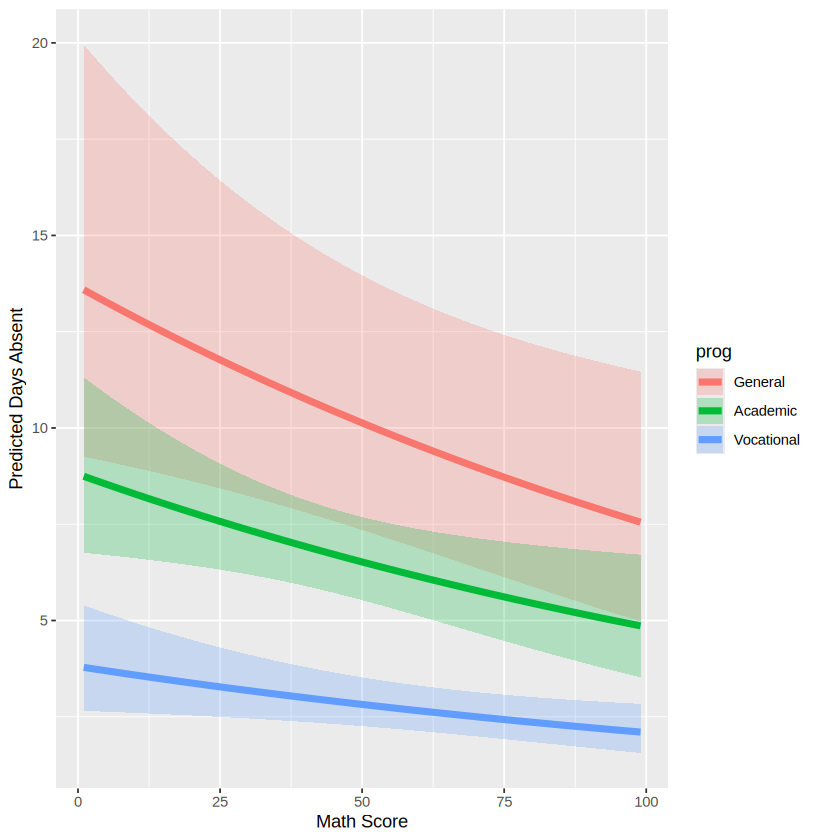

In [35]:
ggplot(newdata2, aes(math, DaysAbsent))+
  geom_ribbon(aes(ymin=LL, ymax=UL, fill=prog), alpha=0.25)+
  geom_line(aes(colour = prog), size = 2)+
  labs(x = "Math Score", y = "Predicted Days Absent")

##중요한 things to consider

It is not recommended that negative binomial models be applied to small
samples.

One common cause of over-dispersion is excess zeros by an additional
data generating process. In this situation, zero-inflated model should be
considered.

If the data generating process does not allow for any 0s (such as the
number of days spent in the hospital), then a zero-truncated model may be
more appropriate.

Count data often have an exposure variable, which indicates the number
of times the event could have happened. This variable should be
incorporated into your negative binomial regression model with the use of
the offset option. See the glm documentation for details

The outcome variable in a negative binomial regression cannot have negative numbers

You will need to use the m1$resid command to obtain the residuals
from our model to check other assumptions
of the negative binomial model (see Cameron and Trivedi (1998) and Dupont (2002) for
more information).